<h3>ME 360 Monte Carlo Integration Project</h3>
Group members: Ken Aoki, Jaycee Hasegawa, Zi Hao Huang, Carl Mercado, Yongjun Yu

In [11]:
import random
import numpy as np
import math

import matplotlib.pyplot as plt
from matplotlib import rc

plt.rcParams['xtick.labelsize']=20     # change the tick label size for x axis
plt.rcParams['ytick.labelsize']=20      # change the tick label size for x axis
plt.rcParams['axes.linewidth']=3        # change the line width of the axis
plt.rcParams['xtick.major.width'] = 3   # change the tick line width of x axis
plt.rcParams['ytick.major.width'] = 3   # change the tick line width of y axis
rc('text', usetex=False)                # disable LaTeX rendering in plots
rc('font',**{'family':'DejaVu Sans'})   # set the font of the plot to be DejaVu Sans

<h4>A. Monte Carlo Integration Method to Estimate Pi</h4>
Specific question: How does the error of the Monte Carlo integration method change based on the number of samples taken when estimating pi?
<br>
<br>
Number of samples: $1*10^{1}$, $1*10^{2}$, $1*10^{3}$, $1*10^{4}$, $1*10^{5}$, $1*10^{6}$
<br>
Number of trials: 100
<br>
<br>
References: https://quants.quest/PiEstimation/

In [12]:
def est_pi(iter):

    # n is number of points used for estimation
    n = int(iter)
    x1 = np.random.uniform(-1, 1, n)
    x2 = np.random.uniform(-1, 1, n)
    
    # Check which points fall inside the unit circle
    inside_circle = x1**2 + x2**2 <= 1
    
    # Estimate of pi
    pi_estimate = 4 * inside_circle.mean()

    return pi_estimate

Text(0.5, 1.0, 'Monte Carlo Integration Error vs Sample Size')

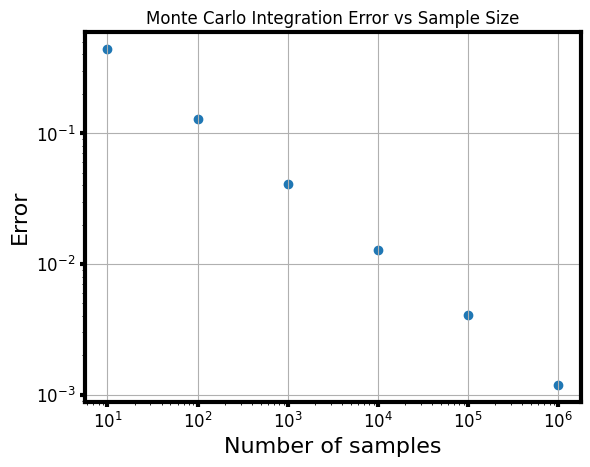

In [32]:
num_trials = 100
samples = [1e1, 1e2, 1e3, 1e4, 1e5, 1e6]
error = []
all_errors = []

# Complete 100 trials. For each trial, estimate pi a variable number of times depending on the samples value.
for row in range(num_trials):
    for col in samples:
        error.append(abs(est_pi(col)-math.pi))
    all_errors.append(error)
    error = []

# Average the error across all trials. 
avg_error = np.mean(all_errors, axis=0)

# Graph results
plt.scatter(samples, avg_error)
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Number of samples', fontsize = 16)
plt.ylabel('Error', fontsize = 16)
plt.grid()
plt.title("Monte Carlo Integration Error vs Sample Size")

<h4>B. Monte Carlo Integration Method with Variable Functions</h4>
Specific question: How does the number of samples required to achieve a given tolerance change based on the function?
<br>
<br>
Functions: $sin(x)$, $e^{x}$, $x^{2}+4x+4$
<br>
Interval: [0, 1]
<br>
Exact answers: elementary antiderivatives of each function
<br>
Tolerance: $0.5*10^{-4}$
<br>
Number of trials: 100
<br>
<br>
References: https://www.geeksforgeeks.org/python/monte-carlo-integration-in-python/


In [14]:
# Declares functions used for parameter sweep
def fun1(x):
    return np.sin(x)

def fun2(x):
    return np.exp(x)

def fun3(x):
    return np.power(x,2) + 4*x + 4

In [15]:
# General monte carlo integration function
# f is function
# a, b are limits of integration
# N = number of points used for estimation
# d = number of dimensions for integration
def mci(f, a, b, N, d=1):
    x_random = np.random.uniform(a, b, (N,d))
    estimate = (b - a)**d * np.mean(f(x_random))
    
    return estimate

In [16]:
# Calculates the number of samples that are needed to achieve a given tolerance
def num_samples(f, ground_truth, a, b, tol, max_iter=10e6):
    N = 1
    while N <= max_iter:
        if abs(mci(f, a, b, N) - ground_truth) <= tol:
            return N
        N += 1
    raise ValueError("Maximum number of iterations reached before given solution tolerance was achieved")

In [17]:
num_trials = 100
tol = 0.5e-4
a = 0
b = 1
avg_samples = []

# Functions for parameter sweep and their elementary antiderivative solutions
functions = [[fun1, -math.cos(b) + math.cos(a)],
             [fun2, math.e**b - math.e**a],
             [fun3, (1/3)*b**3 + 2*b**2 + 4*b - ((1/3)*a**3 + 2*a**2 + 4*a)]]

# Completes 100 trials for each function. For each trial, calculate the nuber of samples needed to achieve a tolerance of 0.5e-4.
for f, truth in functions:
    samples = []  
    for j in range(num_trials):
        samples.append(num_samples(f, truth, a, b, tol))
    avg_samples.append(np.mean(samples))

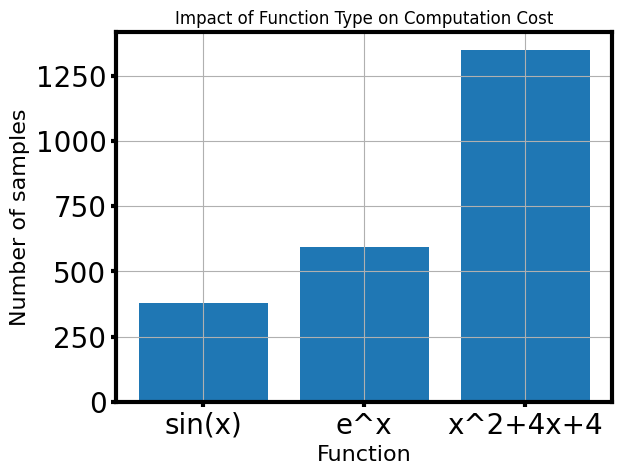

In [18]:
func_names = ["sin(x)", "e^x", "x^2+4x+4"]

# Graph results
plt.bar(func_names, avg_samples)
plt.xlabel('Function', fontsize = 16)
plt.ylabel('Number of samples', fontsize = 16)
plt.title("Impact of Function Type on Computation Cost")
plt.grid()

<h4> C. How do Monte Carlo, trapezoid, and Simpson compare for the same function?</h4>
Specific question: How does the error change based on the method of integration for a given function?
<br>
<br>
Function:  𝑓(𝑥)=𝑒^𝑥
<br>
Interval:  [0,1]
<br>
Exact answer: 𝑒−1
<br>
Function evaluations per run: 101
<br>
Tolerance: $0.5*10^{-4}$
<br>
Number of trials: 100
<br>
<br>
References:
<br>
- https://github.com/Inf1n1ty-8/Applied-Math-Python-Portfolio/blob/main/02_numerical_integration.ipynb
<br>
- https://people.duke.edu/~ccc14/sta-663/MonteCarlo.html
<br>
- HW 3 and HW 6

In [19]:
# Step 1: Set the function and constants
a = 0.0
b = 1.0
n = 100                # 100 subintervals -> 101 points
N = n + 1              # Monte Carlo also uses 101 points
m = 50                 # Simpson: 50 panels, 2 subintervals per panel
num_trials = 100
tol = 0.5e-4
f = fun2

true_value = np.exp(1) - np.exp(0)

print("Exact integral:", true_value)
print("Number of function evaluations:", N)
print("Tolerance:", tol)


Exact integral: 1.718281828459045
Number of function evaluations: 101
Tolerance: 5e-05


In [20]:
# Step 2: Composite Trapezoid Rule

def comp_trap(f, a, b, m=10):
    h = (b-a)/m
    integral = f(a) + f(b)
    for i in range(1, m):
        integral += 2*f(a+i*h)
    return integral*h/2

In [21]:
# Step 3: Composite Simpson's Rule

def comp_simp(f, a, b, m=10):
    h = (b-a)/(2*m)
    integral = f(a) + f(b)
    for i in range(1, 2*m):
        if i % 2 == 1:
            integral += 4*f(a+i*h)
        else:
            integral += 2*f(a+i*h)
    return integral*h/3

In [22]:
# Step 4: Monte Carlo Integration
# Use mci() from Question B.
# Repeat the random estimate 100 times.

np.random.seed(300)

mc_results = []
for i in range(num_trials):
    mc_results.append(mci(f, a, b, N))

mc_errors = []
for result in mc_results:
    mc_errors.append(abs(result - true_value))

mc_result = np.mean(mc_results)
mc_error = np.mean(mc_errors)


In [23]:
# Step 5: Calculate the Trapezoid and Simpson results
# Both use 100 subintervals and 101 points.
# Simpson's rule has 50 panels of 2 subintervals each.

trap_result = comp_trap(f, a, b, n)
simp_result = comp_simp(f, a, b, m)

trap_error = abs(trap_result - true_value)
simp_error = abs(simp_result - true_value)

print("Exact value:", true_value)
print("Monte Carlo mean estimate:", mc_result)
print("Trapezoid estimate:", trap_result)
print("Simpson estimate:", simp_result)

print("Monte Carlo mean absolute error:", mc_error)
print("Trapezoid absolute error:", trap_error)
print("Simpson absolute error:", simp_error)

Exact value: 1.718281828459045
Monte Carlo mean estimate: 1.7253747232265217
Trapezoid estimate: 1.718296147450417
Simpson estimate: 1.7182818285545036
Monte Carlo mean absolute error: 0.036330299180360924
Trapezoid absolute error: 1.4318991371942147e-05
Simpson absolute error: 9.545852996950543e-11


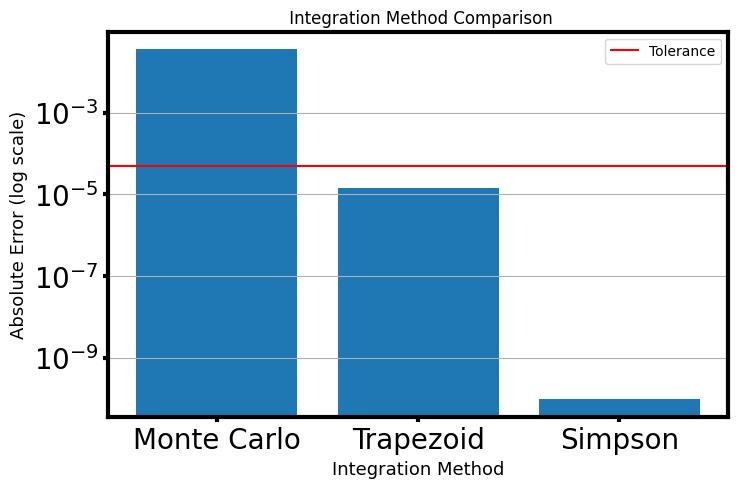

In [24]:
# Step 6: Plot the errors

methods = ["Monte Carlo", "Trapezoid", "Simpson"]
errors = [mc_error, trap_error, simp_error]

plt.figure(figsize=(8, 5))
plt.bar(methods, errors)
plt.axhline(tol, color="red", linestyle="-", label="Tolerance")
plt.legend()
plt.yscale("log")
plt.xlabel("Integration Method", fontsize=13)
plt.ylabel("Absolute Error (log scale)", fontsize=13)
plt.title(" Integration Method Comparison")
plt.grid(True, axis='y')
plt.show()

<h4>D. Monte Carlo Integration Method with Different Dimensions</h4>
Specific question: How does the number of dimensions affect the accuracy of the Monte Carlo integration method?
<br>
<br>
1D curve: $ \int^1_0 x^2 dx $
<br>
2D surface: $ \int^1_0 \int^1_0 \frac{x^2+y^2}{2} dx dy$
<br>
3D volume: $ \int^1_0 \int^1_0 \int^1_0 \frac{x^2+y^2+z^2}{3} dx dy dz$
<br>
<br>
Interval:  [0,1]
<br>
Function evaluations per run: 1000
<br>
Number of trials: 100
<br>

<br>
References: https://medium.com/data-science/a-gentle-introduction-to-monte-carlo-methods-98451674018d

In [25]:
def mean_squares(x):
    return np.mean(np.power(x, 2), axis=1)

In [26]:
N = 1000
num_trials = 100
a = 0
b = 1
# Number of dimensions and analytical solution
dims = [[1, 1/3],
        [2, 1/3],
        [3, 1/3]]
avg_error = []

# Complete 100 trials for each dimension value. For each trial calculate the error of the monte carlo integration method then average the result.
for d, truth in dims:
    error = []
    for i in range(num_trials):
        error.append(abs(mci(mean_squares, a, b, N, d) - truth))
    avg_error.append(np.mean(error))

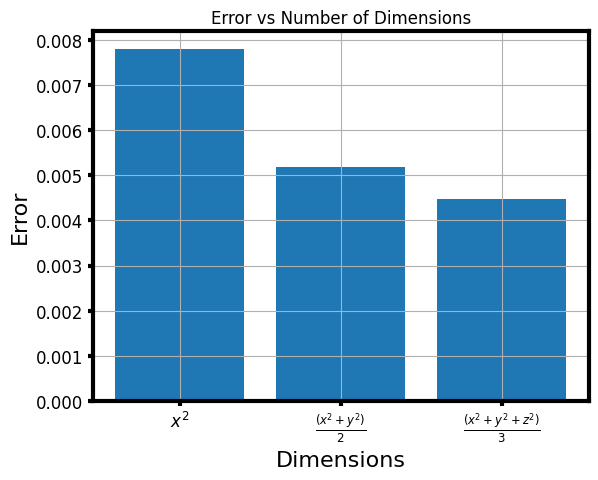

In [27]:
func_names = ["$x^{2}$", r'$\frac{(x^{2}+y^{2})}{2}$', r'$\frac{(x^{2}+y^{2}+z^{2})}{3}$']

# Graph the results
plt.rcParams['xtick.labelsize']=12
plt.rcParams['ytick.labelsize']=12 
plt.bar(func_names, avg_error)
plt.xlabel('Dimensions', fontsize=16)
plt.ylabel('Error', fontsize=16)
plt.title("Error vs Number of Dimensions")
plt.grid()